In [296]:
print("Notebook Restoran Api Api Ikan Bakar siap digunakan.")

Notebook Restoran Api Api Ikan Bakar siap digunakan.


# Analisis Sentimen Review Pelanggan Restoran Api Api Ikan Bakar Menggunakan Machine Learning

Notebook ini digunakan untuk proyek akhir mata kuliah Artificial Intelligence dengan tema bisnis. Proyek ini bertujuan untuk menganalisis sentimen review pelanggan Restoran Api Api Ikan Bakar menggunakan Natural Language Processing dan Machine Learning.

## 1. Import Library

Pada bagian ini, library yang dibutuhkan akan diimpor terlebih dahulu. Library digunakan untuk membaca dataset, membersihkan data, mengolah teks, melakukan visualisasi, membuat model Machine Learning, dan mengevaluasi hasil model.

In [297]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Load Dataset

Dataset yang digunakan adalah Perlis Restaurant Reviews with Sentiment Scores. Dataset ini berisi review pelanggan dari beberapa restoran di Perlis, Malaysia. Pada proyek ini, data akan difokuskan hanya pada Restoran Api Api Ikan Bakar.

In [298]:
df = pd.read_csv("../data/perlis_reviews.csv")

df.head()

,place_id,place_name,review_id_hash,rating,review_text,published_at,published_at_date,response_from_owner_text,response_from_owner_ago,response_from_owner_date,review_likes_count,total_number_of_reviews_by_reviewer,total_number_of_photos_by_reviewer,is_local_guide,review_translated_text,response_from_owner_translated_text,label,score
0,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,77ea2d1c14ffdd8b39195a520c7c2b78,5,"The food is all delicious, the service is the ...",2 hours ago,2024-03-29 09:45:18.362622,NaN,NaN,NaN,0,2.0,NaN,0.0,"Makanan semua sedap, servis terbaik n makanan ...",NaN,positive,0.99730
1,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,1ef9e813fd25201dbdd033344b8374a3,5,NaN,4 days ago,2024-03-25 11:45:18.378274,NaN,NaN,NaN,0,27.0,154.0,1.0,NaN,NaN,NaN,NaN
2,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,aac9fba67d4fd4e03c3b2be0b1bd34d9,5,"Very friendly staff, ready to give tips on wha...",2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,17.0,NaN,0.0,"Staff yg sangat peramah, siap bagi petua apa j...",NaN,positive,0.99732
3,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,9c1a27b04003a9f772beaf13d2c529ac,5,NaN,2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,55.0,174.0,1.0,NaN,NaN,NaN,NaN
4,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,61d85a273250497f1f4e338f2b95cfdd,5,Among the Best seafood avaiable in perlis. The...,2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,69.0,492.0,1.0,NaN,NaN,NaN,NaN


In [299]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29652 entries, 0 to 29651
Data columns (total 18 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   place_id                             29652 non-null  str    
 1   place_name                           29652 non-null  str    
 2   review_id_hash                       29652 non-null  str    
 3   rating                               29652 non-null  int64  
 4   review_text                          13502 non-null  str    
 5   published_at                         29652 non-null  str    
 6   published_at_date                    29652 non-null  str    
 7   response_from_owner_text             1090 non-null   str    
 8   response_from_owner_ago              1133 non-null   str    
 9   response_from_owner_date             1133 non-null   str    
 10  review_likes_count                   29652 non-null  int64  
 11  total_number_of_reviews_by_reviewer  26

In [300]:
print("Jumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns)

Jumlah baris dan kolom: (29652, 18)

Nama kolom:
Index(['place_id', 'place_name', 'review_id_hash', 'rating', 'review_text',
       'published_at', 'published_at_date', 'response_from_owner_text',
       'response_from_owner_ago', 'response_from_owner_date',
       'review_likes_count', 'total_number_of_reviews_by_reviewer',
       'total_number_of_photos_by_reviewer', 'is_local_guide',
       'review_translated_text', 'response_from_owner_translated_text',
       'label', 'score'],
      dtype='str')


## 3. Pengecekan Nama Restoran

Pada bagian ini dilakukan pengecekan nama restoran yang tersedia pada dataset. Langkah ini diperlukan karena proyek akan difokuskan hanya pada review pelanggan Restoran Api Api Ikan Bakar.

In [301]:
df["place_name"].value_counts().head(20)

place_name
Anjung Keli                                        2457
Restoran Api Api Ikan Bakar                        2265
Nasi Kandar Yasmeen Arau                           2009
Warung Tepi Sawah 2769                             1672
Hai Thien Seafood Restaurant Hai Tian Hai Xian     1506
Restaurant Kak Su Laksa                            1436
Ana Burger D' Cafe                                 1348
Chortiez & Co                                      1284
Restoran Suri Masakan Melayu Asli                  1037
Tff Cafe                                            937
Capati Labu Sayong & Nasi Gulai Panas               737
Dunia Yong Tau Foo Jalanan                          729
Restoran Mee Zdin                                   672
Pizza Hut Restaurant Kangar                         618
Restoran Nelayan                                    615
Pokok Sawa                                          561
Ngulang Kopitiam                                    503
Bossku House                         

## 4. Filter Dataset Restoran Api Api Ikan Bakar

Dataset awal berisi review dari beberapa restoran di Perlis, Malaysia. Agar analisis lebih fokus pada satu objek usaha kuliner, data difilter hanya untuk Restoran Api Api Ikan Bakar.

In [302]:
df_api = df[df["place_name"] == "Restoran Api Api Ikan Bakar"].copy()

print("Jumlah data Restoran Api Api Ikan Bakar:", df_api.shape)

df_api.head()

Jumlah data Restoran Api Api Ikan Bakar: (2265, 18)


,place_id,place_name,review_id_hash,rating,review_text,published_at,published_at_date,response_from_owner_text,response_from_owner_ago,response_from_owner_date,review_likes_count,total_number_of_reviews_by_reviewer,total_number_of_photos_by_reviewer,is_local_guide,review_translated_text,response_from_owner_translated_text,label,score
0,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,77ea2d1c14ffdd8b39195a520c7c2b78,5,"The food is all delicious, the service is the ...",2 hours ago,2024-03-29 09:45:18.362622,NaN,NaN,NaN,0,2.0,NaN,0.0,"Makanan semua sedap, servis terbaik n makanan ...",NaN,positive,0.99730
1,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,1ef9e813fd25201dbdd033344b8374a3,5,NaN,4 days ago,2024-03-25 11:45:18.378274,NaN,NaN,NaN,0,27.0,154.0,1.0,NaN,NaN,NaN,NaN
2,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,aac9fba67d4fd4e03c3b2be0b1bd34d9,5,"Very friendly staff, ready to give tips on wha...",2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,17.0,NaN,0.0,"Staff yg sangat peramah, siap bagi petua apa j...",NaN,positive,0.99732
3,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,9c1a27b04003a9f772beaf13d2c529ac,5,NaN,2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,55.0,174.0,1.0,NaN,NaN,NaN,NaN
4,ChIJjTVgsZabTDAR6-U-JJ8hj-Y,Restoran Api Api Ikan Bakar,61d85a273250497f1f4e338f2b95cfdd,5,Among the Best seafood avaiable in perlis. The...,2 weeks ago,2024-03-15 11:45:18.379211,NaN,NaN,NaN,0,69.0,492.0,1.0,NaN,NaN,NaN,NaN


## 5. Pemilihan Kolom Penting

Dataset memiliki banyak kolom, namun tidak semua kolom digunakan dalam proyek ini. Kolom yang digunakan adalah nama restoran, rating, teks ulasan, tanggal ulasan dan label sentimen.

In [303]:
kolom_dipakai = [
    "place_name",
    "rating",
    "review_text",
    "published_at_date",
    "label"
]

df_api = df_api[kolom_dipakai]

df_api.head()

,place_name,rating,review_text,published_at_date,label
0,Restoran Api Api Ikan Bakar,5,"The food is all delicious, the service is the ...",2024-03-29 09:45:18.362622,positive
1,Restoran Api Api Ikan Bakar,5,NaN,2024-03-25 11:45:18.378274,NaN
2,Restoran Api Api Ikan Bakar,5,"Very friendly staff, ready to give tips on wha...",2024-03-15 11:45:18.379211,positive
3,Restoran Api Api Ikan Bakar,5,NaN,2024-03-15 11:45:18.379211,NaN
4,Restoran Api Api Ikan Bakar,5,Among the Best seafood avaiable in perlis. The...,2024-03-15 11:45:18.379211,NaN


## 6. Pembersihan Data Kosong

Pada bagian ini, data yang tidak memiliki teks ulasan atau label sentimen akan dihapus. Teks ulasan diperlukan sebagai input model, sedangkan label sentimen diperlukan sebagai target klasifikasi.

In [304]:
print("Jumlah data sebelum dibersihkan:", df_api.shape)

df_api = df_api.dropna(subset=["review_text", "label"])

print("Jumlah data setelah dibersihkan:", df_api.shape)

Jumlah data sebelum dibersihkan: (2265, 5)
Jumlah data setelah dibersihkan: (580, 5)


## 7. Penyesuaian Nama Kolom

Nama kolom disesuaikan agar lebih mudah dibaca dan lebih rapi ketika digunakan dalam laporan.

In [305]:
df_api = df_api.rename(columns={
    "place_name": "Nama_Restoran",
    "rating": "Rating",
    "review_text": "Teks_Ulasan",
    "published_at_date": "Tanggal_Ulasan",
    "label": "Sentimen"
})

df_api.head()

,Nama_Restoran,Rating,Teks_Ulasan,Tanggal_Ulasan,Sentimen
0,Restoran Api Api Ikan Bakar,5,"The food is all delicious, the service is the ...",2024-03-29 09:45:18.362622,positive
2,Restoran Api Api Ikan Bakar,5,"Very friendly staff, ready to give tips on wha...",2024-03-15 11:45:18.379211,positive
9,Restoran Api Api Ikan Bakar,5,Restaurant by the river. While eating you can ...,2024-03-15 11:45:18.412631,positive
16,Restoran Api Api Ikan Bakar,5,Coconut Milk/Yellow Milk Grilled Fish is the b...,2024-03-08 11:45:19.645761,positive
21,Restoran Api Api Ikan Bakar,5,The food is all delicious. There are fishing b...,2024-02-29 11:45:20.262460,positive


## 8. Data Understanding

Pada bagian ini dilakukan pengecekan awal terhadap dataset, seperti jumlah data, nilai kosong, distribusi sentimen, dan distribusi rating. Tahap ini penting untuk memahami kondisi dataset sebelum masuk ke preprocessing teks dan pembuatan model.

In [306]:
print("Jumlah baris dan kolom:", df_api.shape)
print("\nNama kolom:")
print(df_api.columns)

Jumlah baris dan kolom: (580, 5)

Nama kolom:
Index(['Nama_Restoran', 'Rating', 'Teks_Ulasan', 'Tanggal_Ulasan', 'Sentimen'], dtype='str')


In [307]:
df_api.isnull().sum()

Nama_Restoran     0
Rating            0
Teks_Ulasan       0
Tanggal_Ulasan    0
Sentimen          0
dtype: int64

In [308]:
df_api["Sentimen"].value_counts()

Sentimen
positive    456
negative    124
Name: count, dtype: int64

In [309]:
df_api["Rating"].value_counts().sort_index()

Rating
1     21
2     17
3     46
4    138
5    358
Name: count, dtype: int64

## 9. Visualisasi Distribusi Sentimen

Pada bagian ini dilakukan visualisasi jumlah review berdasarkan label sentimen. Visualisasi ini digunakan untuk melihat perbandingan jumlah review positive dan negative pada dataset Restoran Api Api Ikan Bakar.

In [310]:
sentimen_count = df_api["Sentimen"].value_counts()

sentimen_count

Sentimen
positive    456
negative    124
Name: count, dtype: int64

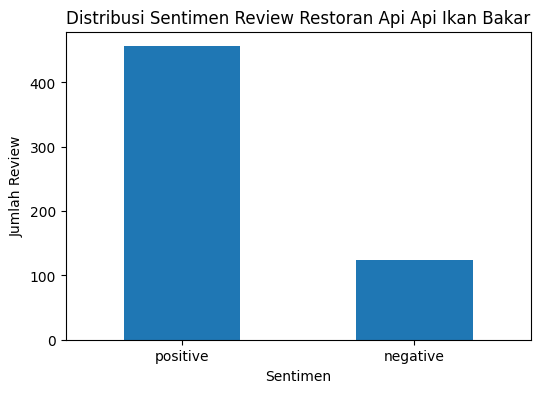

In [311]:
plt.figure(figsize=(6, 4))
sentimen_count.plot(kind="bar")

plt.title("Distribusi Sentimen Review Restoran Api Api Ikan Bakar")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)
plt.show()

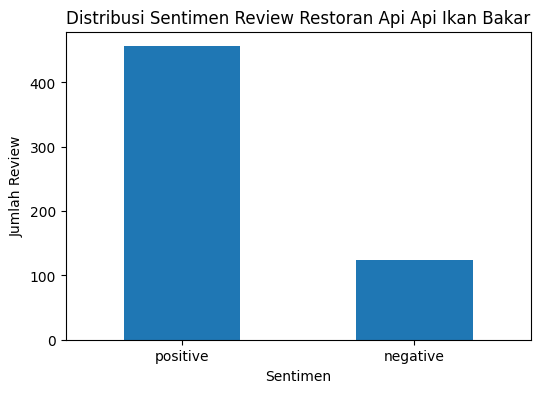

In [312]:
plt.figure(figsize=(6, 4))
sentimen_count.plot(kind="bar")

plt.title("Distribusi Sentimen Review Restoran Api Api Ikan Bakar")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)

plt.savefig("../output/distribusi_sentimen_api_api.png", bbox_inches="tight")
plt.show()

## 10. Visualisasi Distribusi Rating

Pada bagian ini dilakukan visualisasi jumlah review berdasarkan rating pelanggan. Visualisasi rating digunakan untuk melihat penyebaran nilai rating dari pelanggan Restoran Api Api Ikan Bakar.

In [313]:
rating_count = df_api["Rating"].value_counts().sort_index()

rating_count

Rating
1     21
2     17
3     46
4    138
5    358
Name: count, dtype: int64

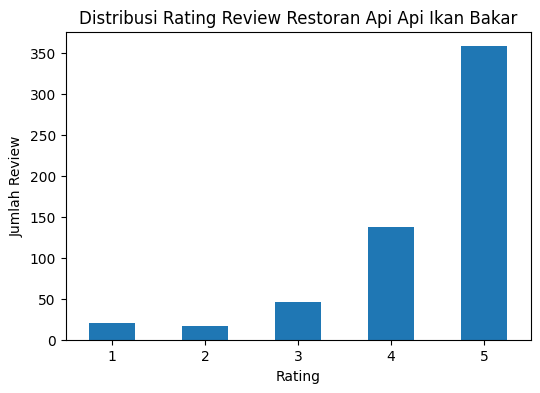

In [314]:
plt.figure(figsize=(6, 4))
rating_count.plot(kind="bar")

plt.title("Distribusi Rating Review Restoran Api Api Ikan Bakar")
plt.xlabel("Rating")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)
plt.show()

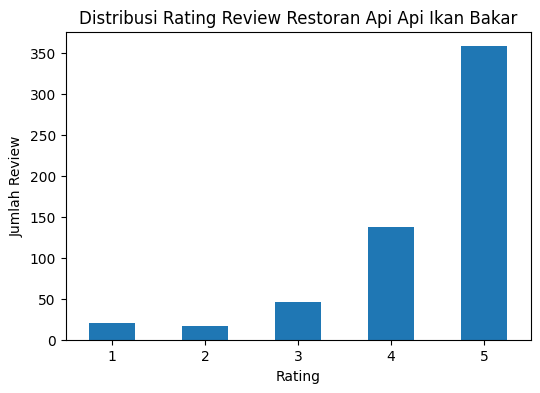

In [315]:
plt.figure(figsize=(6, 4))
rating_count.plot(kind="bar")

plt.title("Distribusi Rating Review Restoran Api Api Ikan Bakar")
plt.xlabel("Rating")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)

plt.savefig("../output/distribusi_rating_api_api.png", bbox_inches="tight")
plt.show()

## 11. Contoh Review Berdasarkan Sentimen

Pada bagian ini ditampilkan beberapa contoh review positive dan negative untuk memahami isi data yang digunakan.

In [316]:
df_api[df_api["Sentimen"] == "positive"][["Rating", "Teks_Ulasan", "Sentimen"]].head(10)

,Rating,Teks_Ulasan,Sentimen
0,5,"The food is all delicious, the service is the ...",positive
2,5,"Very friendly staff, ready to give tips on wha...",positive
9,5,Restaurant by the river. While eating you can ...,positive
16,5,Coconut Milk/Yellow Milk Grilled Fish is the b...,positive
21,5,The food is all delicious. There are fishing b...,positive
27,3,"The food is average, the service is okay, the ...",positive
28,5,Fast service...delicious food..package ready...,positive
38,5,Good place for grilled fish in Perlis. Located...,positive
43,5,"Grilled fish is the tastiest and freshest, eve...",positive
45,5,Delicious food..reasonable price..,positive


In [317]:
df_api[df_api["Sentimen"] == "negative"][["Rating", "Teks_Ulasan", "Sentimen"]].head(10)

,Rating,Teks_Ulasan,Sentimen
35,4,Im surprised because there are so many people,negative
44,4,"Its delicious, especially the moist grilled ye...",negative
58,2,Not my taste. The special thing is that the fi...,negative
67,1,"I hope the shop is by the river, but the order...",negative
88,4,Baked fish in coconut milk is delicious. I wan...,negative
89,5,Its delicious!!!! Worth the queue,negative
92,1,"Too many people. If you want to get a table, y...",negative
97,5,"The best in town, the environment and the food...",negative
107,5,1st time coming here. Sedapp...short waiting p...,negative
109,2,"Booking system, booking people dont come but w...",negative


## 12. Preprocessing Teks

Pada bagian ini, teks ulasan pelanggan dibersihkan sebelum digunakan dalam proses Machine Learning. Tahapan yang dilakukan meliputi mengubah huruf menjadi huruf kecil, menghapus angka, tanda baca, simbol, dan spasi berlebih. Hasil dari tahap ini disimpan pada kolom baru bernama Teks_Bersih.

In [318]:
def bersihkan_teks(teks):
    teks = str(teks).lower()
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks)
    teks = teks.strip()
    return teks

df_api["Teks_Bersih"] = df_api["Teks_Ulasan"].apply(bersihkan_teks)

df_api[["Teks_Ulasan", "Teks_Bersih", "Sentimen"]].head(10)

,Teks_Ulasan,Teks_Bersih,Sentimen
0,"The food is all delicious, the service is the ...",the food is all delicious the service is the b...,positive
2,"Very friendly staff, ready to give tips on wha...",very friendly staff ready to give tips on what...,positive
9,Restaurant by the river. While eating you can ...,restaurant by the river while eating you can e...,positive
16,Coconut Milk/Yellow Milk Grilled Fish is the b...,coconut milk yellow milk grilled fish is the b...,positive
21,The food is all delicious. There are fishing b...,the food is all delicious there are fishing bo...,positive
27,"The food is average, the service is okay, the ...",the food is average the service is okay the at...,positive
28,Fast service...delicious food..package ready...,fast service delicious food package ready,positive
35,Im surprised because there are so many people,im surprised because there are so many people,negative
38,Good place for grilled fish in Perlis. Located...,good place for grilled fish in perlis located ...,positive
43,"Grilled fish is the tastiest and freshest, eve...",grilled fish is the tastiest and freshest ever...,positive


## 13. Pengecekan Teks Setelah Preprocessing

Pada bagian ini dilakukan pengecekan terhadap hasil preprocessing untuk memastikan teks ulasan yang sudah dibersihkan tetap memiliki isi dan dapat digunakan sebagai input model.

In [319]:
df_api["Panjang_Teks_Bersih"] = df_api["Teks_Bersih"].apply(len)

df_api[["Teks_Ulasan", "Teks_Bersih", "Panjang_Teks_Bersih", "Sentimen"]].head(10)

,Teks_Ulasan,Teks_Bersih,Panjang_Teks_Bersih,Sentimen
0,"The food is all delicious, the service is the ...",the food is all delicious the service is the b...,201,positive
2,"Very friendly staff, ready to give tips on wha...",very friendly staff ready to give tips on what...,89,positive
9,Restaurant by the river. While eating you can ...,restaurant by the river while eating you can e...,150,positive
16,Coconut Milk/Yellow Milk Grilled Fish is the b...,coconut milk yellow milk grilled fish is the b...,91,positive
21,The food is all delicious. There are fishing b...,the food is all delicious there are fishing bo...,82,positive
27,"The food is average, the service is okay, the ...",the food is average the service is okay the at...,154,positive
28,Fast service...delicious food..package ready...,fast service delicious food package ready,41,positive
35,Im surprised because there are so many people,im surprised because there are so many people,45,negative
38,Good place for grilled fish in Perlis. Located...,good place for grilled fish in perlis located ...,181,positive
43,"Grilled fish is the tastiest and freshest, eve...",grilled fish is the tastiest and freshest ever...,89,positive


In [320]:
jumlah_teks_kosong = (df_api["Panjang_Teks_Bersih"] == 0).sum()

print("Jumlah teks kosong setelah preprocessing:", jumlah_teks_kosong)

Jumlah teks kosong setelah preprocessing: 0


In [321]:
df_api = df_api[df_api["Panjang_Teks_Bersih"] > 0].copy()

print("Jumlah data setelah menghapus teks kosong:", df_api.shape)

Jumlah data setelah menghapus teks kosong: (580, 7)


## Menentukan Fitur dan Target

Pada bagian ini ditentukan fitur dan target yang akan digunakan dalam model Machine Learning. Fitur yang digunakan adalah teks ulasan yang sudah dibersihkan, sedangkan target yang digunakan adalah label sentimen.

In [322]:
X = df_api["Teks_Bersih"]
y = df_api["Sentimen"]

print("Jumlah data teks:", len(X))
print("Jumlah label:", len(y))

print("\nDistribusi target:")
print(y.value_counts())

Jumlah data teks: 580
Jumlah label: 580

Distribusi target:
Sentimen
positive    456
negative    124
Name: count, dtype: int64


## 14. Ekstraksi Fitur dengan TF-IDF

Pada bagian ini, teks ulasan yang sudah dibersihkan akan diubah menjadi bentuk numerik menggunakan TF-IDF. Proses ini diperlukan karena model Machine Learning tidak dapat membaca teks secara langsung, sehingga teks harus diubah menjadi angka terlebih dahulu.

In [323]:
# Stopwords custom untuk model
# Kata negasi seperti not, no, dan never sengaja TIDAK dibuang
custom_stopwords_model = [
    "the", "and", "is", "are", "was", "were", "a", "an", "to", "of", "in",
    "for", "with", "on", "at", "this", "that", "it", "as", "be", "by", "or",
    "from", "but", "so", "very", "also", "there", "their", "they", "we", "you",
    "i", "my", "me", "our", "your", "he", "she", "his", "her", "them", "will",
    "would", "can", "could", "just", "really", "quite", "much", "many"
]

tfidf = TfidfVectorizer(
    max_features=5000,
    min_df=1,
    max_df=0.95,
    stop_words=custom_stopwords_model,
    ngram_range=(1, 3),
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(X)

print("Ukuran matriks TF-IDF:", X_tfidf.shape)

Ukuran matriks TF-IDF: (580, 5000)


In [324]:
fitur_kata = tfidf.get_feature_names_out()

print("Contoh fitur kata:")
print(fitur_kata[:50])

Contoh fitur kata:
['aa' 'aa cuttlefish' 'aa cuttlefish flour' 'aa flour' 'aa flour thin'
 'aa if' 'aa if kailan' 'aaa' 'aaa alhamdulillah'
 'aaa alhamdulillah toilets' 'aaa baked' 'aaa baked fish' 'aaa parking'
 'aaa parking here' 'aaa salted' 'aaa salted fish' 'aaaa' 'about'
 'accessibility' 'across' 'across street' 'across street dont' 'add'
 'added' 'additional' 'advance' 'afford' 'affordable' 'after'
 'after eating' 'after ordering' 'again' 'again next' 'again next time'
 'again when' 'air' 'air conditioning' 'air conditioning delicious'
 'alhamdulillah' 'all' 'all delicious' 'all food' 'all food delicious'
 'all fresh' 'all good' 'all side' 'all side dishes' 'almost' 'already'
 'always']


## 15. Pembagian Data Training dan Testing

Pada bagian ini, dataset dibagi menjadi data training dan data testing. Data training digunakan untuk melatih model, sedangkan data testing digunakan untuk menguji performa model pada data yang belum pernah dipelajari sebelumnya.

In [325]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 464
Jumlah data testing: 116


In [326]:
print("Distribusi label data training:")
print(y_train.value_counts())

print("\nDistribusi label data testing:")
print(y_test.value_counts())

Distribusi label data training:
Sentimen
positive    365
negative     99
Name: count, dtype: int64

Distribusi label data testing:
Sentimen
positive    91
negative    25
Name: count, dtype: int64


## 16. Training Model Naive Bayes

Pada bagian ini, model pertama yang digunakan adalah Naive Bayes. Model ini sering digunakan dalam klasifikasi teks karena sederhana, cepat, dan cukup efektif untuk data berbasis kata seperti hasil TF-IDF.

In [327]:
model_nb = MultinomialNB()

model_nb.fit(X_train, y_train)

print("Model Naive Bayes berhasil dilatih.")

Model Naive Bayes berhasil dilatih.


In [328]:
y_pred_nb = model_nb.predict(X_test)

print("Prediksi Naive Bayes selesai.")

Prediksi Naive Bayes selesai.


In [329]:
akurasi_nb = accuracy_score(y_test, y_pred_nb)

print("Akurasi Naive Bayes:", akurasi_nb)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Akurasi Naive Bayes: 0.7844827586206896

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        25
    positive       0.78      1.00      0.88        91

    accuracy                           0.78       116
   macro avg       0.39      0.50      0.44       116
weighted avg       0.62      0.78      0.69       116



c:\Kuliah\Semester 6\Teori AI\sentiment-api-api-ikan-bakar\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Kuliah\Semester 6\Teori AI\sentiment-api-api-ikan-bakar\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Kuliah\Semester 6\Teori AI\sentiment-api-api-ikan-bakar\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

## 17. Training Model Logistic Regression

Pada bagian ini, model kedua yang digunakan adalah Logistic Regression. Model ini digunakan sebagai pembanding dari Naive Bayes. Karena jumlah data positive lebih banyak dibandingkan negative, parameter class_weight="balanced" digunakan agar model lebih memperhatikan kedua kelas sentimen secara lebih seimbang.

In [330]:
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_lr.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


In [331]:
y_pred_lr = model_lr.predict(X_test)

print("Prediksi Logistic Regression selesai.")

Prediksi Logistic Regression selesai.


In [332]:
akurasi_lr = accuracy_score(y_test, y_pred_lr)

print("Akurasi Logistic Regression:", akurasi_lr)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Akurasi Logistic Regression: 0.7844827586206896

Classification Report:
              precision    recall  f1-score   support

    negative       0.50      0.48      0.49        25
    positive       0.86      0.87      0.86        91

    accuracy                           0.78       116
   macro avg       0.68      0.67      0.68       116
weighted avg       0.78      0.78      0.78       116



## 18. Training Model Support Vector Machine

Pada bagian ini, model ketiga yang digunakan adalah Support Vector Machine. Model ini digunakan sebagai pembanding karena sering digunakan dalam klasifikasi teks dan dapat bekerja dengan baik pada data hasil ekstraksi fitur TF-IDF. Parameter class_weight="balanced" digunakan karena jumlah data positive lebih banyak dibandingkan negative.

In [333]:
model_svm = LinearSVC(class_weight="balanced")

model_svm.fit(X_train, y_train)

print("Model SVM berhasil dilatih.")

Model SVM berhasil dilatih.


In [334]:
y_pred_svm = model_svm.predict(X_test)

print("Prediksi SVM selesai.")

Prediksi SVM selesai.


In [335]:
akurasi_svm = accuracy_score(y_test, y_pred_svm)

print("Akurasi SVM:", akurasi_svm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Akurasi SVM: 0.7586206896551724

Classification Report:
              precision    recall  f1-score   support

    negative       0.43      0.36      0.39        25
    positive       0.83      0.87      0.85        91

    accuracy                           0.76       116
   macro avg       0.63      0.61      0.62       116
weighted avg       0.74      0.76      0.75       116



## 19. Perbandingan Hasil Model

Pada bagian ini, hasil evaluasi dari beberapa model Machine Learning dibandingkan. Model yang dibandingkan adalah Naive Bayes, Logistic Regression, dan Support Vector Machine. Perbandingan dilakukan berdasarkan akurasi dan performa model dalam mengenali kelas positive serta negative.

In [336]:
hasil_model = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Support Vector Machine"
    ],
    "Akurasi": [
        akurasi_nb,
        akurasi_lr,
        akurasi_svm
    ],
    "Catatan": [
        "Akurasi cukup tinggi, tetapi lemah mengenali negative",
        "Lebih seimbang dalam mengenali positive dan negative",
        "Cukup baik, tetapi masih lebih rendah dari Logistic Regression"
    ]
})

hasil_model

,Model,Akurasi,Catatan
0,Naive Bayes,0.784483,"Akurasi cukup tinggi, tetapi lemah mengenali n..."
1,Logistic Regression,0.784483,Lebih seimbang dalam mengenali positive dan ne...
2,Support Vector Machine,0.758621,"Cukup baik, tetapi masih lebih rendah dari Log..."


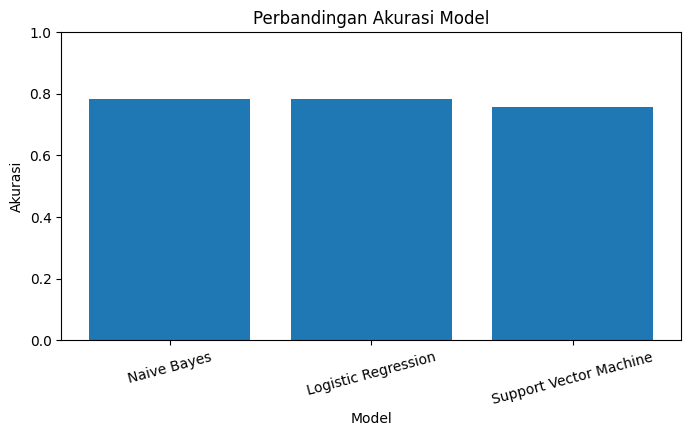

In [337]:
plt.figure(figsize=(8, 4))
plt.bar(hasil_model["Model"], hasil_model["Akurasi"])

plt.title("Perbandingan Akurasi Model")
plt.xlabel("Model")
plt.ylabel("Akurasi")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

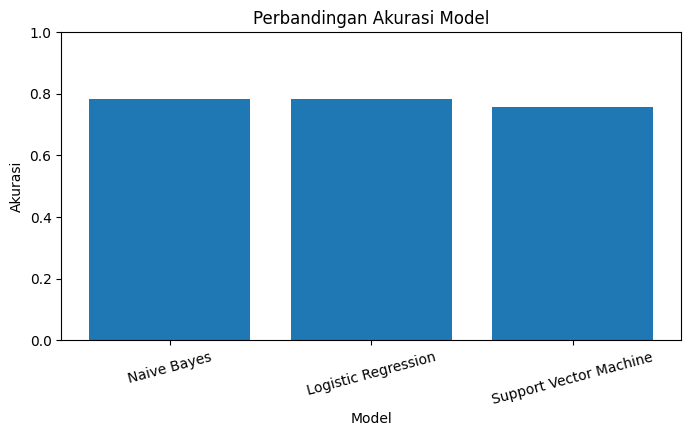

In [338]:
plt.figure(figsize=(8, 4))
plt.bar(hasil_model["Model"], hasil_model["Akurasi"])

plt.title("Perbandingan Akurasi Model")
plt.xlabel("Model")
plt.ylabel("Akurasi")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.savefig("../output/perbandingan_akurasi_model.png", bbox_inches="tight")
plt.show()

Naive Bayes memiliki akurasi cukup tinggi, tetapi kurang baik dalam mengenali sentimen negative. Hal ini terlihat dari nilai recall negative yang rendah. Logistic Regression memiliki performa yang lebih seimbang, sehingga lebih sesuai digunakan sebagai model utama dalam proyek ini.

## 20. Confusion Matrix Model Logistic Regression

Confusion matrix digunakan untuk melihat hasil prediksi model secara lebih detail. Pada bagian ini, confusion matrix dibuat berdasarkan model Logistic Regression karena model tersebut memiliki performa yang lebih seimbang dalam mengenali sentimen positive dan negative.

In [339]:
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["negative", "positive"])

cm_lr

array([[12, 13],
       [12, 79]])

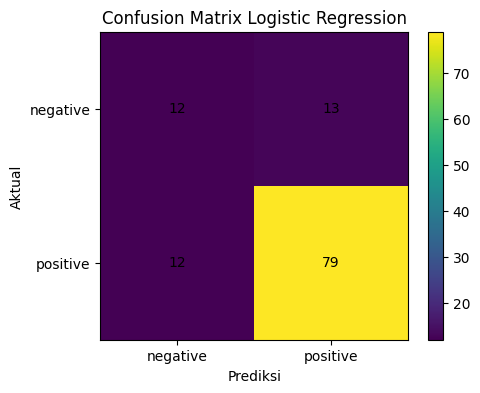

In [340]:
label_sentimen = ["negative", "positive"]

plt.figure(figsize=(5, 4))
plt.imshow(cm_lr)

plt.title("Confusion Matrix Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], label_sentimen)
plt.yticks([0, 1], label_sentimen)

for i in range(len(label_sentimen)):
    for j in range(len(label_sentimen)):
        plt.text(j, i, cm_lr[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

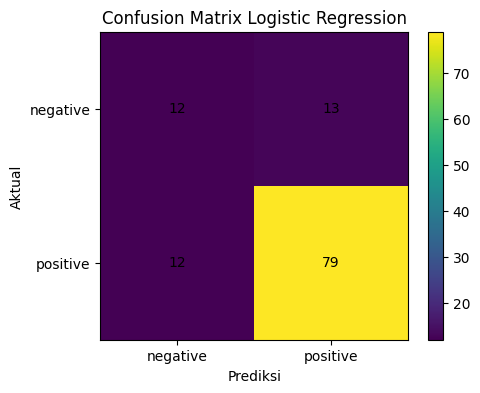

In [341]:
label_sentimen = ["negative", "positive"]

plt.figure(figsize=(5, 4))
plt.imshow(cm_lr)

plt.title("Confusion Matrix Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], label_sentimen)
plt.yticks([0, 1], label_sentimen)

for i in range(len(label_sentimen)):
    for j in range(len(label_sentimen)):
        plt.text(j, i, cm_lr[i, j], ha="center", va="center")

plt.colorbar()

plt.savefig("../output/confusion_matrix_logistic_regression.png", bbox_inches="tight")
plt.show()

## 21. Demo Prediksi Review Baru

Pada bagian ini, model Logistic Regression yang telah dilatih digunakan untuk memprediksi sentimen dari review baru. Review baru akan dibersihkan terlebih dahulu, kemudian diubah menjadi fitur numerik menggunakan TF-IDF, lalu diprediksi oleh model.

In [342]:
def prediksi_sentimen_review(teks_review):
    teks_bersih = bersihkan_teks(teks_review)
    teks_tfidf = tfidf.transform([teks_bersih])
    hasil_prediksi = model_lr.predict(teks_tfidf)[0]
    
    return hasil_prediksi

In [343]:
review_positif = "The grilled fish was fresh and delicious, the service was fast, and the place was comfortable."

hasil_positif = prediksi_sentimen_review(review_positif)

print("Review:", review_positif)
print("Prediksi sentimen:", hasil_positif)

Review: The grilled fish was fresh and delicious, the service was fast, and the place was comfortable.
Prediksi sentimen: positive


In [344]:
review_negatif = "The service was very slow, the food was cold, and the price was too expensive."

hasil_negatif = prediksi_sentimen_review(review_negatif)

print("Review:", review_negatif)
print("Prediksi sentimen:", hasil_negatif)

Review: The service was very slow, the food was cold, and the price was too expensive.
Prediksi sentimen: negative


## 22. Demo Review Campuran

Pada bagian ini dilakukan pengujian menggunakan review baru yang lebih kompleks. Review campuran berisi unsur positif dan negatif dalam satu kalimat, sehingga dapat digunakan untuk melihat bagaimana model memprediksi sentimen pada teks yang lebih sulit.

In [345]:
data_demo = [
    {
        "Nama_Reviewer": "Cesa",
        "Teks_Ulasan": "The grilled fish was delicious and fresh, but the service was quite slow."
    },
    {
        "Nama_Reviewer": "Azmi",
        "Teks_Ulasan": "The place is comfortable and the view is nice, but the food was too salty."
    },
    {
        "Nama_Reviewer": "Milan",
        "Teks_Ulasan": "The staff were friendly, the food was tasty, and the price was reasonable."
    },
    {
        "Nama_Reviewer": "Stenly",
        "Teks_Ulasan": "I waited too long for my order and the food was not worth the price."
    },
    {
        "Nama_Reviewer": "Invoker",
        "Teks_Ulasan": "The restaurant has a good atmosphere, but the service needs improvement."
    }
]

hasil_demo = []

for data in data_demo:
    teks_bersih = bersihkan_teks(data["Teks_Ulasan"])
    prediksi = prediksi_sentimen_review(data["Teks_Ulasan"])
    
    hasil_demo.append({
        "Nama_Reviewer": data["Nama_Reviewer"],
        "Teks_Ulasan": data["Teks_Ulasan"],
        "Teks_Bersih": teks_bersih,
        "Prediksi_Sentimen": prediksi
    })

df_demo = pd.DataFrame(hasil_demo)

df_demo

,Nama_Reviewer,Teks_Ulasan,Teks_Bersih,Prediksi_Sentimen
0,Cesa,"The grilled fish was delicious and fresh, but ...",the grilled fish was delicious and fresh but t...,positive
1,Azmi,"The place is comfortable and the view is nice,...",the place is comfortable and the view is nice ...,positive
2,Milan,"The staff were friendly, the food was tasty, a...",the staff were friendly the food was tasty and...,positive
3,Stenly,I waited too long for my order and the food wa...,i waited too long for my order and the food wa...,negative
4,Invoker,"The restaurant has a good atmosphere, but the ...",the restaurant has a good atmosphere but the s...,positive


In [346]:
df_demo.to_csv("../output/hasil_demo_prediksi_review.csv", index=False)

print("Hasil demo prediksi berhasil disimpan.")

Hasil demo prediksi berhasil disimpan.


## 23. Penanganan Data Tidak Seimbang dengan Oversampling

Berdasarkan hasil eksplorasi, jumlah review positive lebih banyak dibandingkan review negative. Kondisi ini dapat membuat model lebih cenderung memprediksi review sebagai positive dan kurang baik dalam mengenali review negative.

Untuk mengurangi masalah tersebut, dilakukan oversampling pada kelas negative di data training. Oversampling dilakukan dengan menggandakan data negative yang sudah ada pada data training hingga jumlahnya seimbang dengan kelas positive. Data testing tidak diubah agar evaluasi tetap dilakukan pada data asli.

In [347]:
from sklearn.utils import resample

# Mengubah y_train menjadi array agar mudah diproses
y_train_array = np.array(y_train)

# Mengambil indeks kelas positive dan negative
positive_idx = np.where(y_train_array == "positive")[0]
negative_idx = np.where(y_train_array == "negative")[0]

print("Distribusi data training sebelum oversampling:")
print("Positive:", len(positive_idx))
print("Negative:", len(negative_idx))

# Melakukan oversampling pada kelas negative
negative_upsampled_idx = resample(
    negative_idx,
    replace=True,
    n_samples=len(positive_idx),
    random_state=42
)

# Menggabungkan data positive asli dan negative hasil oversampling
balanced_idx = np.concatenate([positive_idx, negative_upsampled_idx])

# Mengacak ulang agar data tidak berurutan berdasarkan kelas
np.random.seed(42)
np.random.shuffle(balanced_idx)

# Membuat data training baru yang sudah seimbang
X_train_balanced = X_train[balanced_idx]
y_train_balanced = y_train_array[balanced_idx]

print("\nDistribusi data training setelah oversampling:")
print(pd.Series(y_train_balanced).value_counts())

Distribusi data training sebelum oversampling:
Positive: 365
Negative: 99

Distribusi data training setelah oversampling:
negative    365
positive    365
Name: count, dtype: int64


## 24. Training Logistic Regression Setelah Oversampling

Setelah data training diseimbangkan, model Logistic Regression dilatih ulang menggunakan data training hasil oversampling. Tujuannya adalah untuk melihat apakah kemampuan model dalam mengenali review negative menjadi lebih baik.

In [348]:
model_lr_os = LogisticRegression(
    max_iter=2000,
    class_weight={"negative": 2.0, "positive": 1.0}
)

model_lr_os.fit(X_train_balanced, y_train_balanced)

print("Model Logistic Regression dengan oversampling dan bobot negative berhasil dilatih.")

Model Logistic Regression dengan oversampling dan bobot negative berhasil dilatih.


In [349]:
y_pred_lr_os = model_lr_os.predict(X_test)

akurasi_lr_os = accuracy_score(y_test, y_pred_lr_os)

print("Akurasi Logistic Regression + Oversampling:", akurasi_lr_os)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_os))

Akurasi Logistic Regression + Oversampling: 0.6896551724137931

Classification Report:
              precision    recall  f1-score   support

    negative       0.40      0.88      0.55        25
    positive       0.95      0.64      0.76        91

    accuracy                           0.69       116
   macro avg       0.68      0.76      0.66       116
weighted avg       0.83      0.69      0.72       116



## 25. Threshold Tuning untuk Meningkatkan Deteksi Sentimen Negative

Pada bagian ini dilakukan pengaturan threshold prediksi untuk kelas negative. Threshold digunakan agar model lebih sensitif dalam mendeteksi review negative, karena review negative penting sebagai bahan evaluasi restoran.

In [350]:
proba_test = model_lr_os.predict_proba(X_test)

negative_index = list(model_lr_os.classes_).index("negative")
negative_proba = proba_test[:, negative_index]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    y_pred_threshold = np.where(
        negative_proba >= threshold,
        "negative",
        "positive"
    )
    
    print("=" * 60)
    print("Threshold negative:", threshold)
    print("Akurasi:", accuracy_score(y_test, y_pred_threshold))
    print(classification_report(y_test, y_pred_threshold))

Threshold negative: 0.3
Akurasi: 0.4482758620689655
              precision    recall  f1-score   support

    negative       0.28      1.00      0.44        25
    positive       1.00      0.30      0.46        91

    accuracy                           0.45       116
   macro avg       0.64      0.65      0.45       116
weighted avg       0.85      0.45      0.45       116

Threshold negative: 0.35
Akurasi: 0.5172413793103449
              precision    recall  f1-score   support

    negative       0.31      1.00      0.47        25
    positive       1.00      0.38      0.56        91

    accuracy                           0.52       116
   macro avg       0.65      0.69      0.51       116
weighted avg       0.85      0.52      0.54       116

Threshold negative: 0.4
Akurasi: 0.5517241379310345
              precision    recall  f1-score   support

    negative       0.32      0.96      0.48        25
    positive       0.98      0.44      0.61        91

    accuracy             

## 26. Threshold Final Model Oversampling

Berdasarkan hasil threshold tuning, threshold 0.50 digunakan sebagai threshold final karena masih memiliki akurasi yang paling baik pada model oversampling dan tetap meningkatkan kemampuan model dalam mengenali sentimen negative.

In [351]:
threshold_negative_final = 0.50

proba_test = model_lr_os.predict_proba(X_test)

negative_index = list(model_lr_os.classes_).index("negative")
negative_proba = proba_test[:, negative_index]

y_pred_lr_os_final = np.where(
    negative_proba >= threshold_negative_final,
    "negative",
    "positive"
)

akurasi_lr_os_final = accuracy_score(y_test, y_pred_lr_os_final)

print("Evaluasi Final Logistic Regression + Oversampling + Threshold")
print("Threshold negative:", threshold_negative_final)
print("Akurasi:", akurasi_lr_os_final)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_os_final, zero_division=0))

Evaluasi Final Logistic Regression + Oversampling + Threshold
Threshold negative: 0.5
Akurasi: 0.6896551724137931

Classification Report:
              precision    recall  f1-score   support

    negative       0.40      0.88      0.55        25
    positive       0.95      0.64      0.76        91

    accuracy                           0.69       116
   macro avg       0.68      0.76      0.66       116
weighted avg       0.83      0.69      0.72       116



## 27. Confusion Matrix Logistic Regression Setelah Oversampling

Confusion matrix digunakan untuk melihat jumlah prediksi benar dan salah pada masing-masing kelas sentimen. Pada bagian ini, confusion matrix dibuat untuk model Logistic Regression setelah oversampling.

In [352]:
cm_lr_os_final = confusion_matrix(
    y_test,
    y_pred_lr_os_final,
    labels=["negative", "positive"]
)

cm_lr_os_final

array([[22,  3],
       [33, 58]])

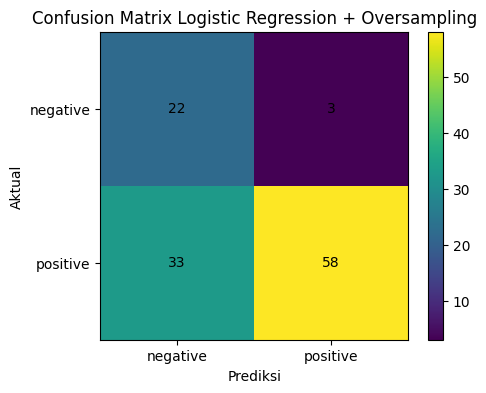

In [353]:
label_sentimen = ["negative", "positive"]

plt.figure(figsize=(5, 4))
plt.imshow(cm_lr_os)

plt.title("Confusion Matrix Logistic Regression + Oversampling")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], label_sentimen)
plt.yticks([0, 1], label_sentimen)

for i in range(len(label_sentimen)):
    for j in range(len(label_sentimen)):
        plt.text(j, i, cm_lr_os[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

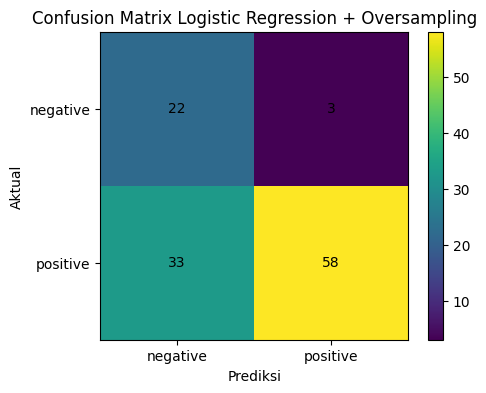

In [354]:
label_sentimen = ["negative", "positive"]

plt.figure(figsize=(5, 4))
plt.imshow(cm_lr_os)

plt.title("Confusion Matrix Logistic Regression + Oversampling")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], label_sentimen)
plt.yticks([0, 1], label_sentimen)

for i in range(len(label_sentimen)):
    for j in range(len(label_sentimen)):
        plt.text(j, i, cm_lr_os[i, j], ha="center", va="center")

plt.colorbar()

plt.savefig("../output/confusion_matrix_logistic_regression_oversampling.png", bbox_inches="tight")
plt.show()

## 28. Perbandingan Model Setelah Oversampling

Pada bagian ini dilakukan perbandingan hasil evaluasi model sebelum dan setelah oversampling. Perbandingan tidak hanya dilihat dari akurasi, tetapi juga dari kemampuan model dalam mengenali sentimen negative.

In [355]:
def ambil_metrik_model(y_true, y_pred, nama_model):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )
    
    return {
        "Model": nama_model,
        "Akurasi": accuracy_score(y_true, y_pred),
        "Precision Negative": report["negative"]["precision"],
        "Recall Negative": report["negative"]["recall"],
        "F1 Negative": report["negative"]["f1-score"],
        "Precision Positive": report["positive"]["precision"],
        "Recall Positive": report["positive"]["recall"],
        "F1 Positive": report["positive"]["f1-score"],
        "Macro Avg F1": report["macro avg"]["f1-score"]
    }

hasil_model_lanjutan = pd.DataFrame([
    ambil_metrik_model(y_test, y_pred_nb, "Naive Bayes"),
    ambil_metrik_model(y_test, y_pred_lr, "Logistic Regression"),
    ambil_metrik_model(y_test, y_pred_svm, "Support Vector Machine"),
    ambil_metrik_model(y_test, y_pred_lr_os, "Logistic Regression + Oversampling"),
    ambil_metrik_model(y_test, y_pred_lr_os_final, "Logistic Regression + Oversampling + Threshold")
])

hasil_model_lanjutan

,Model,Akurasi,Precision Negative,Recall Negative,F1 Negative,Precision Positive,Recall Positive,F1 Positive,Macro Avg F1
0,Naive Bayes,0.784483,0.000000,0.00,0.000000,0.784483,1.000000,0.879227,0.439614
1,Logistic Regression,0.784483,0.500000,0.48,0.489796,0.858696,0.868132,0.863388,0.676592
2,Support Vector Machine,0.758621,0.428571,0.36,0.391304,0.831579,0.868132,0.849462,0.620383
3,Logistic Regression + Oversampling,0.689655,0.400000,0.88,0.550000,0.950820,0.637363,0.763158,0.656579
4,Logistic Regression + Oversampling + Threshold,0.689655,0.400000,0.88,0.550000,0.950820,0.637363,0.763158,0.656579


In [356]:
hasil_model_lanjutan.to_csv("../output/hasil_evaluasi_model_lanjutan.csv", index=False)

print("Tabel evaluasi model lanjutan berhasil disimpan.")

Tabel evaluasi model lanjutan berhasil disimpan.


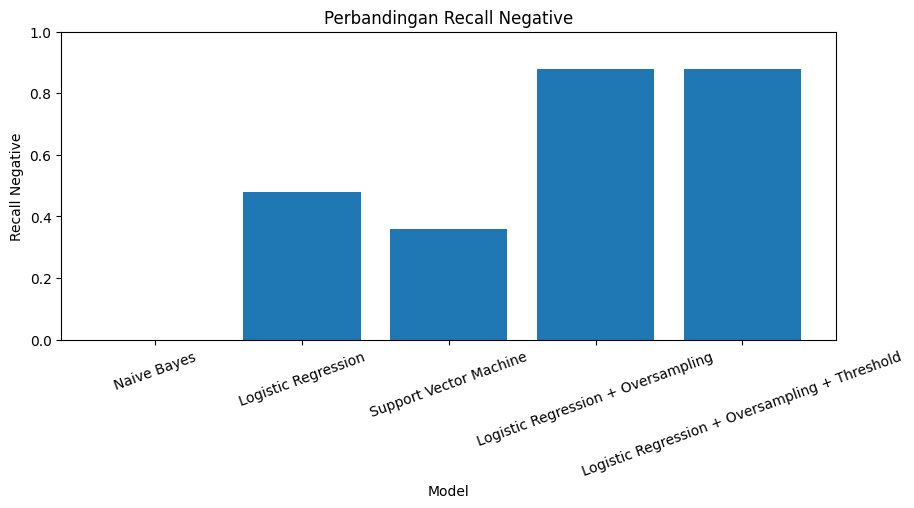

In [357]:
plt.figure(figsize=(10, 4))
plt.bar(hasil_model_lanjutan["Model"], hasil_model_lanjutan["Recall Negative"])

plt.title("Perbandingan Recall Negative")
plt.xlabel("Model")
plt.ylabel("Recall Negative")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

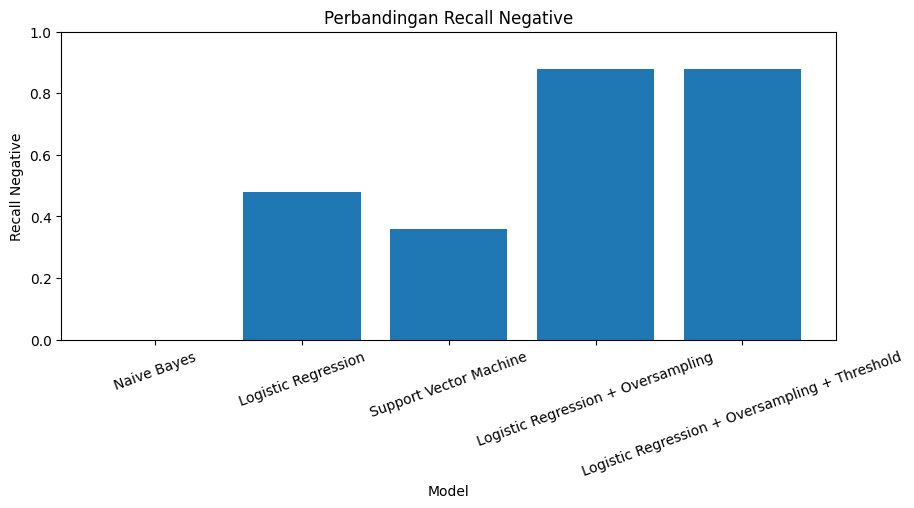

In [358]:
plt.figure(figsize=(10, 4))
plt.bar(hasil_model_lanjutan["Model"], hasil_model_lanjutan["Recall Negative"])

plt.title("Perbandingan Recall Negative")
plt.xlabel("Model")
plt.ylabel("Recall Negative")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.savefig("../output/perbandingan_recall_negative.png", bbox_inches="tight")
plt.show()

## 29. Demo Prediksi Final Menggunakan Model Oversampling

Pada bagian ini, model Logistic Regression setelah oversampling digunakan untuk memprediksi sentimen dari review baru. Model ini digunakan karena sudah dilatih dengan data training yang lebih seimbang antara kelas positive dan negative.

In [359]:
def prediksi_sentimen_review_final(teks_review, threshold_negative=0.50):
    teks_bersih = bersihkan_teks(teks_review)
    teks_tfidf = tfidf.transform([teks_bersih])
    
    proba = model_lr_os.predict_proba(teks_tfidf)[0]
    
    negative_index = list(model_lr_os.classes_).index("negative")
    positive_index = list(model_lr_os.classes_).index("positive")
    
    proba_negative = proba[negative_index]
    proba_positive = proba[positive_index]
    
    if proba_negative >= threshold_negative:
        hasil_prediksi = "negative"
    else:
        hasil_prediksi = "positive"
    
    return hasil_prediksi, proba_positive, proba_negative

In [360]:
data_demo_final = [
    {
        "Nama_Reviewer": "Cesa",
        "Teks_Ulasan": "The grilled fish was fresh and delicious, the service was fast, and the place was comfortable."
    },
    {
        "Nama_Reviewer": "Azmi",
        "Teks_Ulasan": "The service was very slow, the food was cold, and the price was too expensive."
    },
    {
        "Nama_Reviewer": "Milan",
        "Teks_Ulasan": "The food was good, but the service needs improvement."
    },
    {
        "Nama_Reviewer": "Stenly",
        "Teks_Ulasan": "Bad service, dirty table, and the food was not worth the price."
    },
    {
        "Nama_Reviewer": "Hangga",
        "Teks_Ulasan": "The restaurant has a nice view, the grilled fish tastes great, the service was fast, and the price was reasonable."
    }
]

hasil_demo_final = []

for data in data_demo_final:
    teks_bersih = bersihkan_teks(data["Teks_Ulasan"])
    
    prediksi, proba_positive, proba_negative = prediksi_sentimen_review_final(
        data["Teks_Ulasan"],
        threshold_negative=threshold_negative_final
    )
    
    hasil_demo_final.append({
        "Nama_Reviewer": data["Nama_Reviewer"],
        "Teks_Ulasan": data["Teks_Ulasan"],
        "Teks_Bersih": teks_bersih,
        "Probabilitas_Positive": proba_positive,
        "Probabilitas_Negative": proba_negative,
        "Prediksi_Sentimen": prediksi
    })

df_demo_final = pd.DataFrame(hasil_demo_final)

df_demo_final

,Nama_Reviewer,Teks_Ulasan,Teks_Bersih,Probabilitas_Positive,Probabilitas_Negative,Prediksi_Sentimen
0,Cesa,"The grilled fish was fresh and delicious, the ...",the grilled fish was fresh and delicious the s...,0.624850,0.375150,positive
1,Azmi,"The service was very slow, the food was cold, ...",the service was very slow the food was cold an...,0.388757,0.611243,negative
2,Milan,"The food was good, but the service needs impro...",the food was good but the service needs improv...,0.741956,0.258044,positive
3,Stenly,"Bad service, dirty table, and the food was not...",bad service dirty table and the food was not w...,0.437715,0.562285,negative
4,Hangga,"The restaurant has a nice view, the grilled fi...",the restaurant has a nice view the grilled fis...,0.624424,0.375576,positive


## 30. Analisis Kata dan Frasa Terbanyak pada Review Positive dan Negative

Pada bagian ini dilakukan analisis kata dan frasa yang paling sering muncul pada review positive dan negative. Analisis ini digunakan untuk membantu memahami hal-hal yang sering dibahas pelanggan, sehingga dapat menjadi bahan evaluasi bagi restoran.

Analisis dilakukan menggunakan CountVectorizer dengan unigram dan bigram. Stopwords dibuat secara custom agar kata negasi seperti not, no, dan never tidak ikut terhapus, karena kata tersebut penting dalam analisis sentimen.

In [361]:
from sklearn.feature_extraction.text import CountVectorizer

custom_stopwords = [
    "the", "and", "is", "are", "was", "were", "a", "an", "to", "of", "in",
    "for", "with", "on", "at", "this", "that", "it", "as", "be", "by", "or",
    "from", "but", "so", "very", "also", "there", "their", "they", "we", "you",
    "i", "my", "me", "our", "your", "he", "she", "his", "her", "them", "will",
    "would", "can", "could", "just", "really", "quite", "much", "many"
]

def get_top_keywords(text_series, n_words=15):
    vectorizer = CountVectorizer(
        stop_words=custom_stopwords,
        ngram_range=(1, 2),
        min_df=2
    )
    
    bow_matrix = vectorizer.fit_transform(text_series)
    total_words = bow_matrix.sum(axis=0)
    
    words_freq = [
        (word, total_words[0, idx])
        for word, idx in vectorizer.vocabulary_.items()
    ]
    
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    
    return pd.DataFrame(words_freq[:n_words], columns=["Kata/Frasa", "Frekuensi"])

In [362]:
df_positive = df_api[df_api["Sentimen"] == "positive"]
df_negative = df_api[df_api["Sentimen"] == "negative"]

top_keywords_positive = get_top_keywords(df_positive["Teks_Bersih"], n_words=15)
top_keywords_negative = get_top_keywords(df_negative["Teks_Bersih"], n_words=15)

print("Top kata/frasa pada review positive:")
display(top_keywords_positive)

print("Top kata/frasa pada review negative:")
display(top_keywords_negative)

Top kata/frasa pada review positive:


,Kata/Frasa,Frekuensi
0,delicious,205
1,food,145
2,fish,141
3,best,133
4,grilled,107
5,grilled fish,91
6,price,77
7,good,71
8,its,65
9,service,56


Top kata/frasa pada review negative:


,Kata/Frasa,Frekuensi
0,fish,93
1,its,60
2,food,60
3,not,53
4,grilled,47
5,delicious,44
6,people,41
7,grilled fish,38
8,if,37
9,dont,34
